# Task 2 — Exploratory data analysis (player segment)

Revised 2026-11-12 data. Covers schema, target balance, missingness, numeric and categorical features vs `segment`, correlations, mutual information, and train/test drift. Test is only compared on feature distributions (no labels exist). Figures go to `assets/eda-*.png` at 300 dpi.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import ks_2samp
from sklearn.feature_selection import mutual_info_classif

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/train.csv").is_file())
ASSETS = ROOT / "assets"
ASSETS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")


def save(fig, name):
    fig.savefig(ASSETS / f"eda-{name}.png", dpi=300, bbox_inches="tight")
    plt.show()


train = pd.read_csv(ROOT / "data/train.csv")
test = pd.read_csv(ROOT / "data/test.csv")
TARGET, ID = "segment", "player_id"
features = [c for c in train.columns if c not in (TARGET, ID)]
cat_cols = train[features].select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in features if c not in cat_cols]
print(train.shape, test.shape, f"numeric={len(num_cols)} categorical={len(cat_cols)}")
assert train[ID].is_unique and set(train[ID]).isdisjoint(test[ID])

(104000, 46) (25889, 45) numeric=34 categorical=10


## 1. Schema and summary statistics

In [2]:
display(train[num_cols].describe().T.round(3))
display(train[cat_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
play_frequency,95977.0,12.139,7.081,1.000,6.438,11.414,16.895,45.103
avg_session_duration,95999.0,107.530,54.147,20.001,64.392,102.860,144.152,384.269
total_playtime_hours,95993.0,1704.786,944.942,100.004,968.432,1643.098,2346.654,6019.906
login_streak,96044.0,55.069,35.312,0.000,27.000,52.000,79.000,244.000
days_since_last_login,95995.0,45.937,20.801,0.000,31.320,45.754,60.083,132.869
total_spending_thb,96035.0,34323.517,22145.758,501.186,16433.375,31691.384,49093.524,142934.433
avg_monthly_spending,95919.0,3305.152,1936.702,100.142,1778.659,3155.140,4604.265,12555.758
spending_frequency,96033.0,16.983,9.655,1.000,9.342,16.217,23.504,63.914
friend_count,95996.0,107.452,64.842,0.000,56.000,103.000,151.000,428.000
team_play_percentage,95857.0,50.344,19.704,5.000,36.772,50.288,63.825,100.000


,count,unique,top,freq
region,76776,4,AS,19314
platform,95879,3,PC,32056
device_type,95984,4,Tablet,24344
payment_method,71943,3,Wallet,24149
language,96087,6,JP,16115
account_status,96036,2,Active,48133
player_type_tag,96129,4,Casual,24147
engagement_level,95838,4,Mid,38383
loyalty_tier,95975,5,Silver,31513
skill_tier,95979,5,Bronze,24107


## 2. Target distribution

,count,share
segment,,
0,40957,0.3938
1,26032,0.2503
2,21029,0.2022
3,15982,0.1537


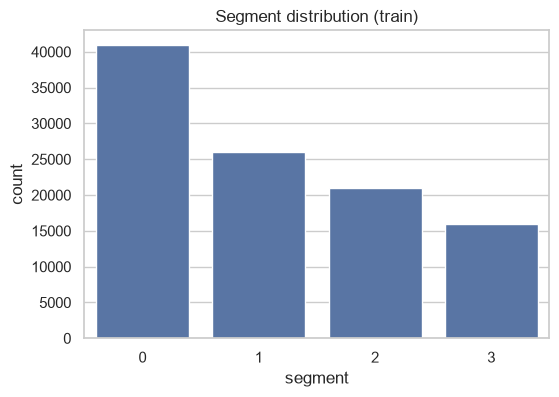

In [3]:
counts = train[TARGET].value_counts().sort_index()
display(pd.DataFrame({"count": counts, "share": (counts / len(train)).round(4)}))
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x=train[TARGET], ax=ax)
ax.set_title("Segment distribution (train)")
save(fig, "target-distribution")

## 3. Missing values

,train,test
payment_method,0.3082,0.3040
region,0.2618,0.2609
engagement_level,0.0785,0.0774
team_play_percentage,0.0783,0.0757
platform,0.0781,0.0755
random_metric_2,0.0781,0.0771
ranked_participation_rate,0.0778,0.0788
avg_monthly_spending,0.0777,0.0762
tournament_entries,0.0774,0.0774
chat_activity_score,0.0773,0.0761


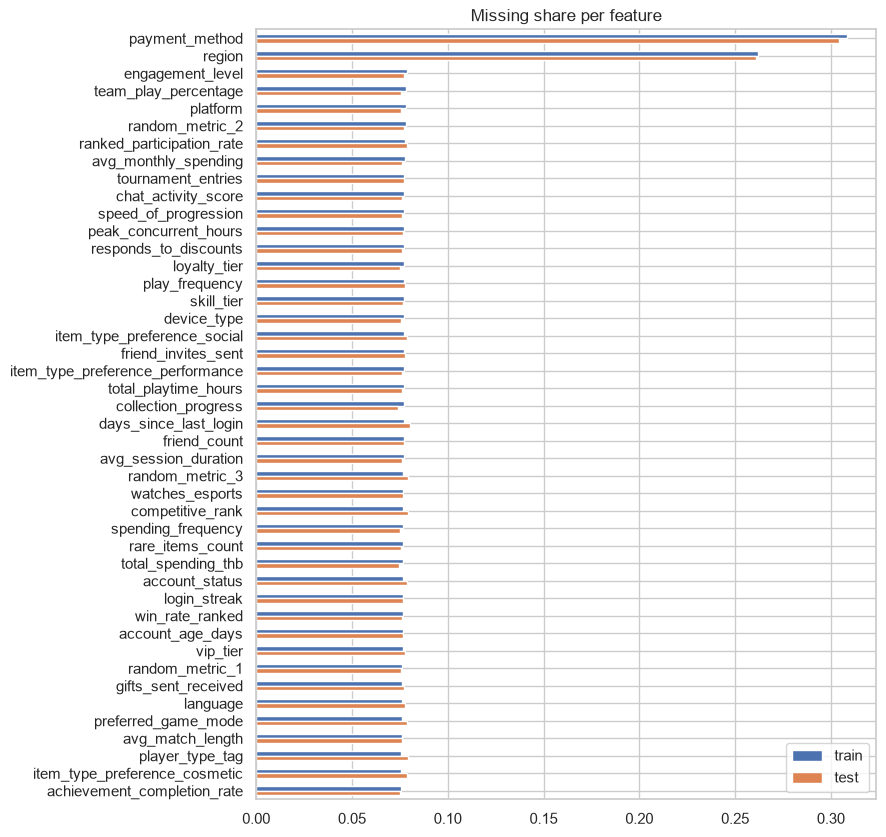

segment,0,1,2,3
row_0,,,,
0,0.416,0.244,0.194,0.146
1,0.392,0.247,0.203,0.158
2,0.397,0.246,0.202,0.155
3,0.393,0.250,0.207,0.150
4,0.391,0.252,0.202,0.155
5,0.396,0.250,0.200,0.155
6,0.392,0.256,0.200,0.152
7,0.386,0.258,0.206,0.150
8,0.400,0.250,0.189,0.160


,mean_seg_present,mean_seg_missing
payment_method,1.116,1.116
region,1.119,1.105
engagement_level,1.116,1.115
team_play_percentage,1.116,1.111
platform,1.115,1.128


In [4]:
miss = pd.DataFrame({"train": train[features].isna().mean(), "test": test[features].isna().mean()})
miss = miss.sort_values("train", ascending=False)
display(miss.head(15).round(4))
fig, ax = plt.subplots(figsize=(8, 10))
miss.plot.barh(ax=ax)
ax.invert_yaxis()
ax.set_title("Missing share per feature")
save(fig, "missing-values")
row_missing = train[features].isna().sum(axis=1)
display(pd.crosstab(row_missing.clip(upper=8), train[TARGET], normalize="index").round(3))
# Does missingness itself carry signal? Segment mix when a column is missing vs present.
flag = {c: train.groupby(train[c].isna())[TARGET].mean() for c in miss.index[:5]}
display(
    pd.DataFrame(flag)
    .T.rename(columns={False: "mean_seg_present", True: "mean_seg_missing"})
    .round(3)
)

## 4. Numeric features by segment

segment,0,1,2,3
play_frequency,9.875,13.479,10.273,13.906
avg_session_duration,90.174,119.033,93.696,123.018
total_playtime_hours,1388.667,1976.764,1469.985,2015.053
login_streak,44.000,61.000,46.000,63.000
days_since_last_login,52.463,37.216,49.797,36.605
total_spending_thb,26139.271,28611.495,38179.359,45092.713
avg_monthly_spending,2564.963,2841.573,3797.574,4525.632
spending_frequency,13.178,14.617,19.500,23.147
friend_count,87.000,123.000,90.000,126.000
team_play_percentage,48.476,52.329,49.093,53.099


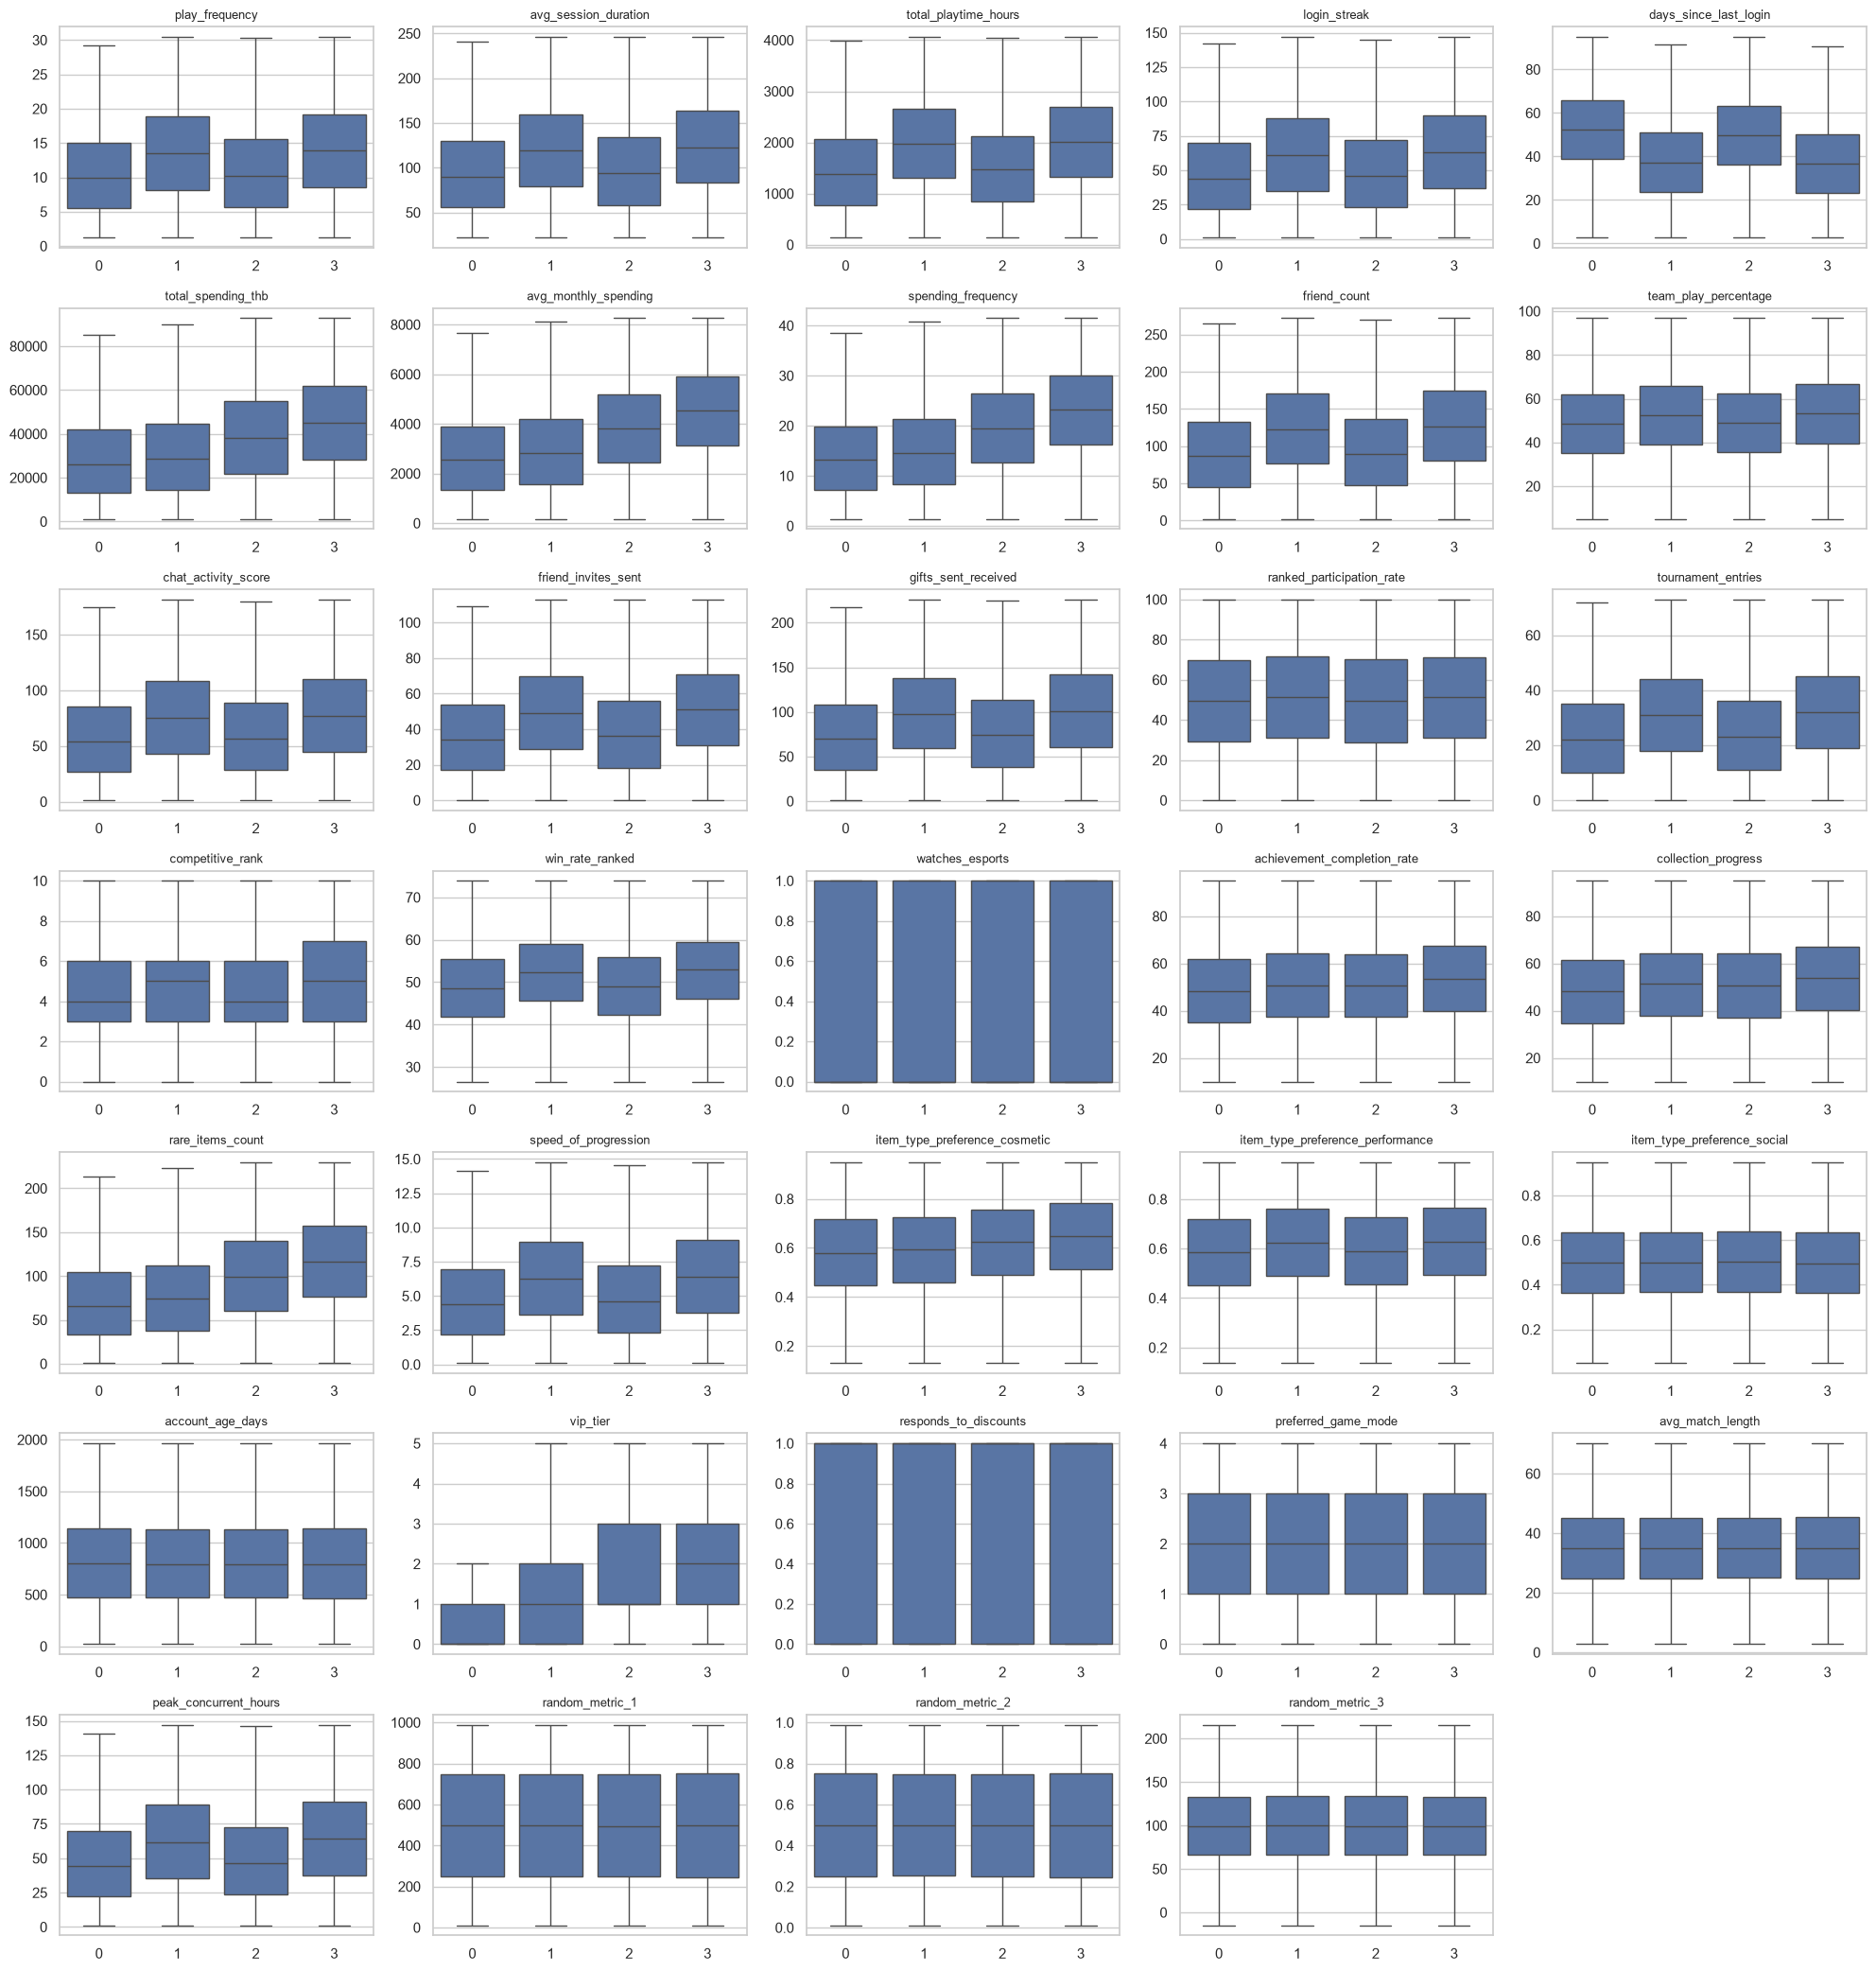

In [5]:
medians = train.groupby(TARGET)[num_cols].median().T
display(medians.round(3))
ncol = 5
nrow = int(np.ceil(len(num_cols) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow))
for ax, col in zip(axes.flat, num_cols, strict=False):
    lo, hi = train[col].quantile([0.01, 0.99])
    sns.boxplot(x=train[TARGET], y=train[col].clip(lo, hi), ax=ax, showfliers=False)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes.flat[len(num_cols) :]:
    ax.remove()
fig.tight_layout()
save(fig, "numeric-by-segment")

Skewness: heavy-tailed spend/playtime columns may benefit from log transforms for linear or neural models.

In [6]:
display(
    train[num_cols].skew().sort_values(key=abs, ascending=False).head(12).round(2).to_frame("skew")
)

,skew
vip_tier,0.94
total_spending_thb,0.61
chat_activity_score,0.57
peak_concurrent_hours,0.56
speed_of_progression,0.55
play_frequency,0.55
login_streak,0.55
tournament_entries,0.54
rare_items_count,0.54
friend_invites_sent,0.50


## 5. Categorical features by segment

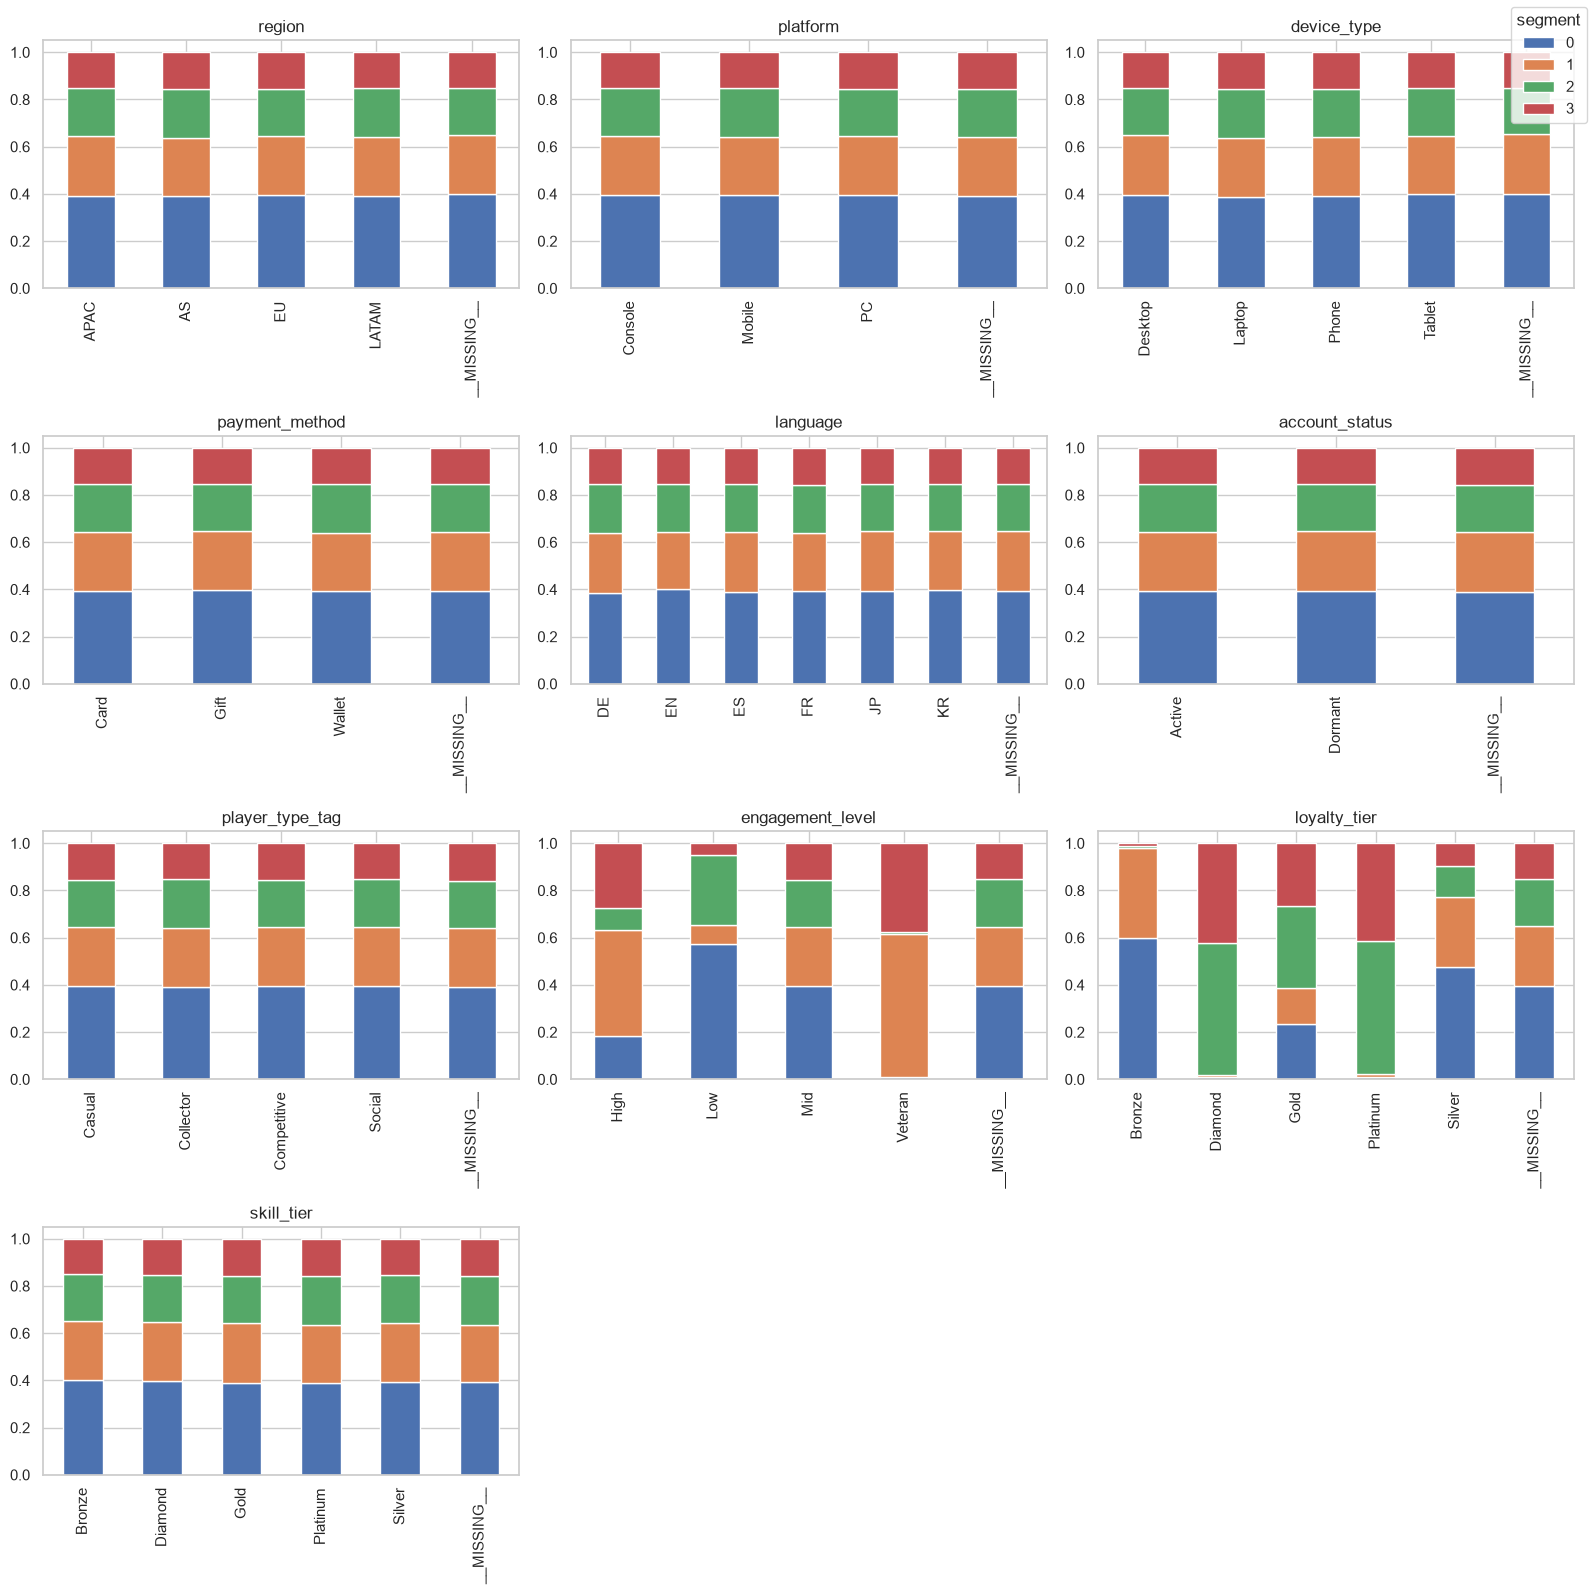

,cardinality
region,4
platform,3
device_type,4
payment_method,3
language,6
account_status,2
player_type_tag,4
engagement_level,4
loyalty_tier,5
skill_tier,5


In [7]:
nrow = int(np.ceil(len(cat_cols) / 3))
fig, axes = plt.subplots(nrow, 3, figsize=(16, 4 * nrow))
for ax, col in zip(axes.flat, cat_cols, strict=False):
    tab = pd.crosstab(train[col].fillna("__MISSING__"), train[TARGET], normalize="index")
    tab.plot.bar(stacked=True, ax=ax, legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.flat[len(cat_cols) :]:
    ax.remove()
fig.legend(*axes.flat[0].get_legend_handles_labels(), title="segment", loc="upper right")
fig.tight_layout()
save(fig, "categorical-by-segment")
display(train[cat_cols].nunique().to_frame("cardinality"))

## 6. Correlation among numeric features

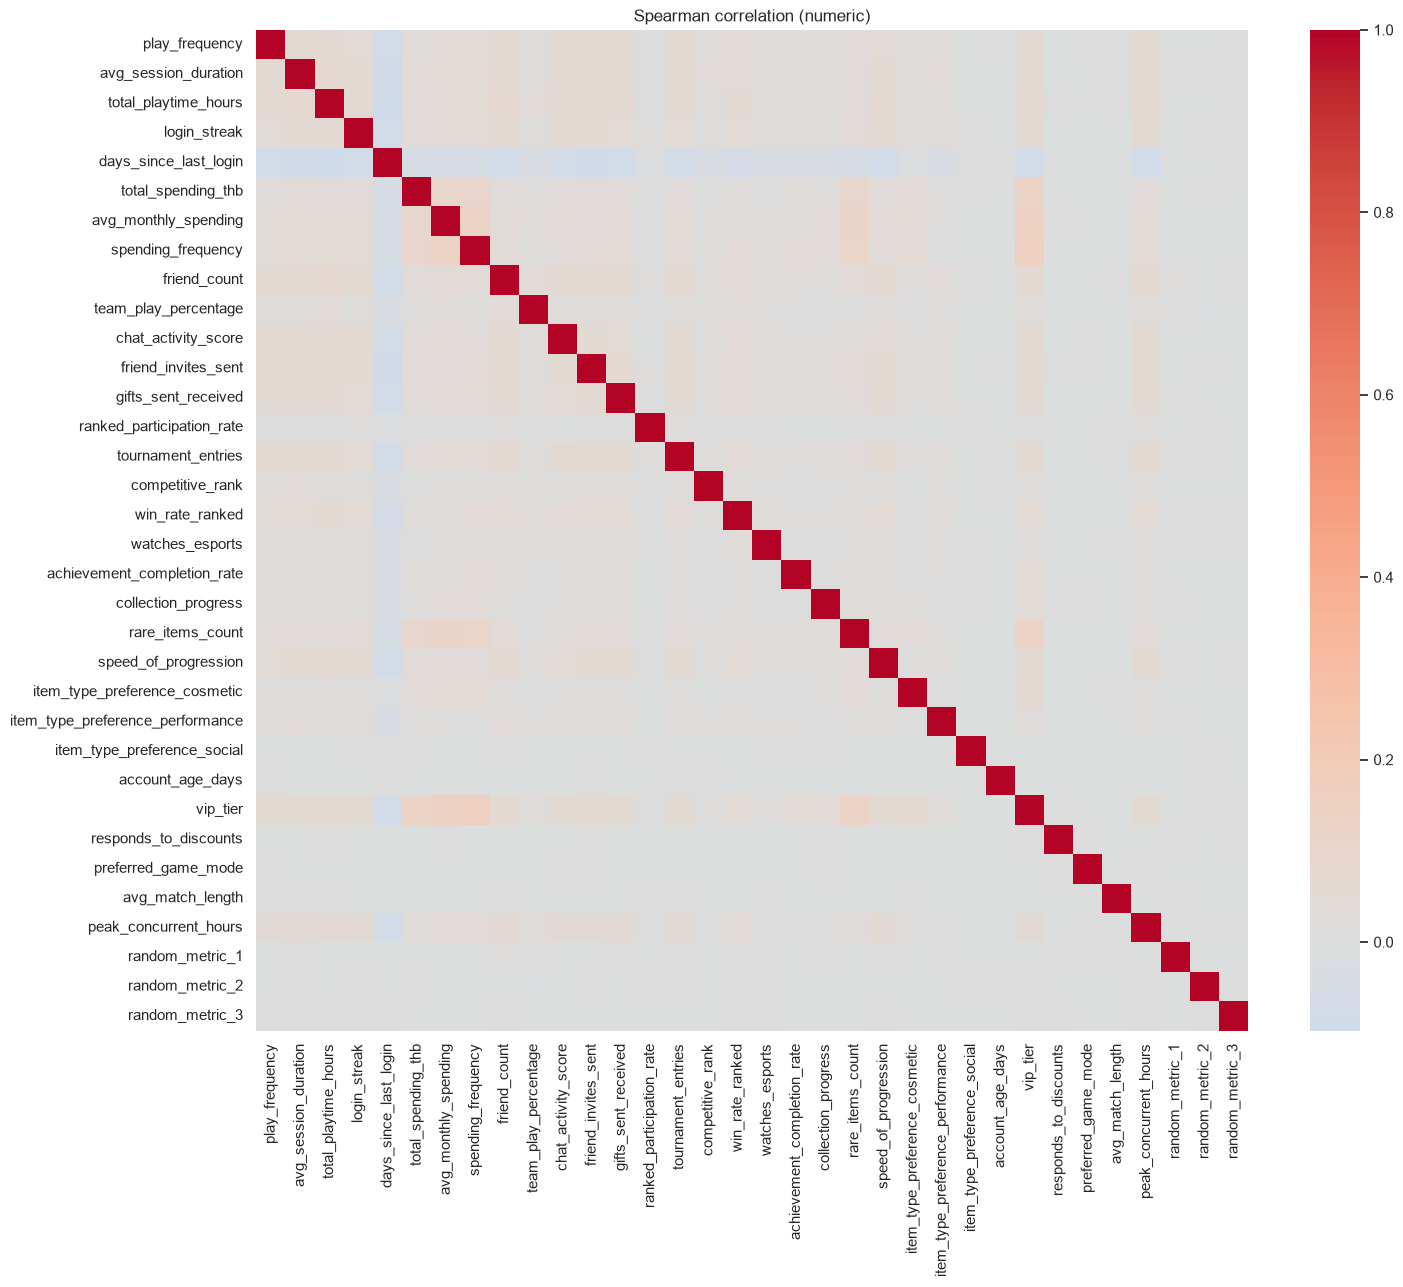

,,rho
spending_frequency,vip_tier,0.153
avg_monthly_spending,vip_tier,0.147
rare_items_count,vip_tier,0.127
avg_monthly_spending,spending_frequency,0.123
total_spending_thb,vip_tier,0.123
avg_monthly_spending,rare_items_count,0.113
spending_frequency,rare_items_count,0.107
total_spending_thb,spending_frequency,0.102
total_playtime_hours,days_since_last_login,-0.097
total_spending_thb,avg_monthly_spending,0.094


In [8]:
corr = train[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, xticklabels=True, yticklabels=True)
ax.set_title("Spearman correlation (numeric)")
save(fig, "correlation-heatmap")
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
display(
    pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(15).round(3).to_frame("rho")
)

## 7. Feature relevance (mutual information with segment)

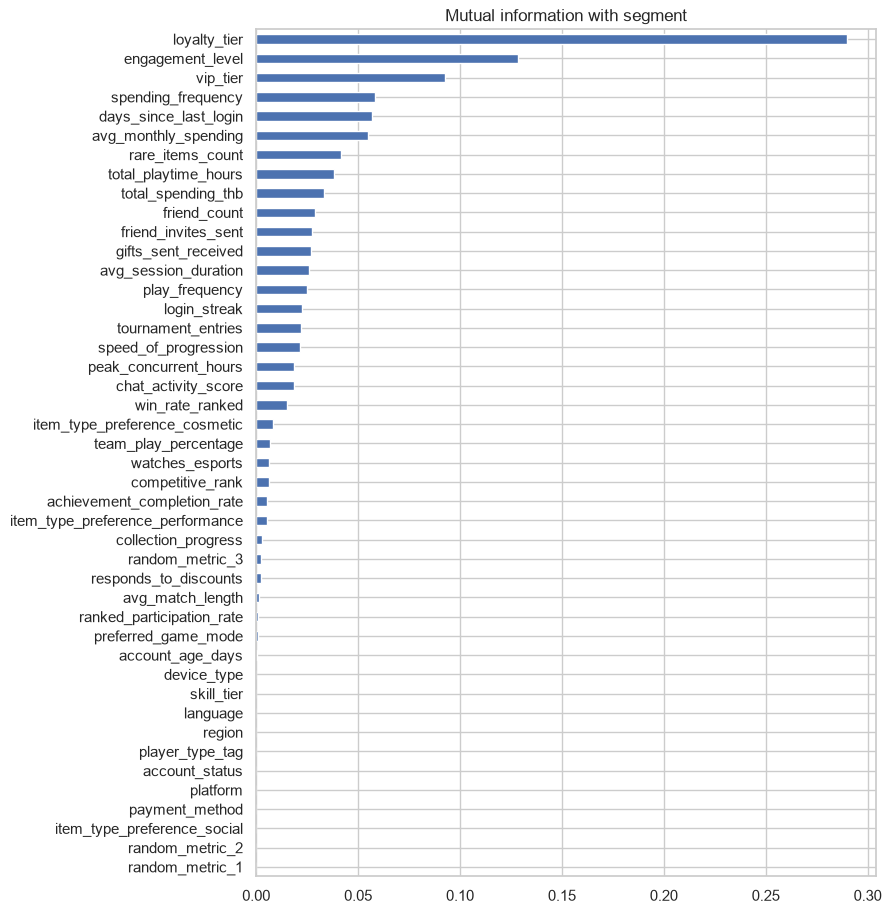

,lowest MI
region,0.0
player_type_tag,0.0
account_status,0.0
platform,0.0
payment_method,0.0
item_type_preference_social,0.0
random_metric_2,0.0
random_metric_1,0.0


In [9]:
x = train[features].copy()
for c in cat_cols:
    x[c] = x[c].fillna("__MISSING__").astype("category").cat.codes
x[num_cols] = x[num_cols].fillna(x[num_cols].median())
mi = mutual_info_classif(
    x, train[TARGET], discrete_features=[c in cat_cols for c in features], random_state=42
)
mi = pd.Series(mi, index=features).sort_values(ascending=False)
mi.to_csv(ASSETS / "eda-mutual-information.csv", header=["mutual_information"])
fig, ax = plt.subplots(figsize=(8, 11))
mi.plot.barh(ax=ax)
ax.invert_yaxis()
ax.set_title("Mutual information with segment")
save(fig, "mutual-information")
display(mi.tail(8).round(4).to_frame("lowest MI"))  # random_metric_* should sit near zero

## 8. Train vs test drift (features only)

In [10]:
drift = pd.DataFrame(
    {c: ks_2samp(train[c].dropna(), test[c].dropna()) for c in num_cols},
    index=["ks_stat", "p_value"],
).T.sort_values("ks_stat", ascending=False)
display(drift.head(10).round(4))
for c in cat_cols:
    gap = (train[c].value_counts(normalize=True) - test[c].value_counts(normalize=True)).abs().max()
    print(f"{c}: max category share gap {gap:.4f}")

,ks_stat,p_value
spending_frequency,0.0088,0.1041
random_metric_2,0.0086,0.1200
random_metric_1,0.0075,0.2327
account_age_days,0.0073,0.2593
tournament_entries,0.0072,0.2684
rare_items_count,0.0068,0.3283
random_metric_3,0.0068,0.3456
total_playtime_hours,0.0068,0.3442
login_streak,0.0067,0.3593
item_type_preference_social,0.0066,0.3732


region: max category share gap 0.0052
platform: max category share gap 0.0038
device_type: max category share gap 0.0031
payment_method: max category share gap 0.0046
language: max category share gap 0.0028
account_status: max category share gap 0.0065
player_type_tag: max category share gap 0.0037
engagement_level: max category share gap 0.0017
loyalty_tier: max category share gap 0.0085
skill_tier: max category share gap 0.0032


## 9. Takeaways

Read the outputs above for exact numbers. Things to check when building models:
- Class balance decides whether macro-F1 needs class weights or threshold/prior adjustment.
- Missingness is ~7–8% per column (higher for `region`, `payment_method`); the row-missing table shows whether it is informative — tree models can use NaN directly, MLPs need imputation.
- `random_metric_*` columns are expected noise; low MI supports dropping them.
- Highly correlated pairs indicate redundant features; skewed spend/playtime columns suit log transforms.
- Low KS statistics mean train and test share feature distributions, so CV scores should transfer.